In [1]:
# DHN_THV_3G_R_S_BASE.py
#
# Outputs:
#   archetypes/DHN_THV_3G_R_S_BASE/nodes.csv   — node table
#   archetypes/DHN_THV_3G_R_S_BASE/pipes.csv   — pipe table
#   archetypes/DHN_THV_3G_R_S_BASE/graph.png   — topology plot
#
# Usage:
#   python dhn_benchmark/networks/thv_radial.py

In [4]:
# ---------------------------------------------------------
# TOPOLOGY
# ---------------------------------------------------------

NODES_S = [
    # id          type           x      y
    ("src_s",    "source",       0,     0),

    ("a_s",      "junction",     0,   300),
    ("b_s",      "junction",   300,     0),
    ("c_s",      "junction",     0,   600),
    ("d_s",      "junction",   600,     0),

    ("sub1_s",   "substation", -150,  300),
    ("sub2_s",   "substation",  150,  300),

    ("sub6_s",   "substation",  300, -150),
    ("sub7_s",   "substation",  300,  150),

    ("sub3_s",   "substation", -150,  600),
    ("sub4_s",   "substation",  150,  600),
    ("sub5_s",   "substation",    0,  750),

    ("sub8_s",   "substation",  600,  150),
    ("sub9_s",   "substation",  600, -150),
    ("sub10_s",  "substation",  750,    0),
]

NODES_R = [
    (nid.replace("_s", "_r"), ntype, x, y)
    for nid, ntype, x, y in NODES_S
]

NODES = NODES_S + NODES_R

EDGES_S = [
    ("src_s", "a_s"),
    ("src_s", "b_s"),
    ("a_s",   "c_s"),
    ("b_s",   "d_s"),
    ("a_s",   "sub1_s"),
    ("a_s",   "sub2_s"),
    ("b_s",   "sub6_s"),
    ("b_s",   "sub7_s"),
    ("c_s",   "sub3_s"),
    ("c_s",   "sub4_s"),
    ("c_s",   "sub5_s"),
    ("d_s",   "sub8_s"),
    ("d_s",   "sub9_s"),
    ("d_s",   "sub10_s"),
]

EDGES_R = [
    (v.replace("_s", "_r"), u.replace("_s", "_r"))
    for u, v in EDGES_S
]

EDGES = EDGES_S + EDGES_R

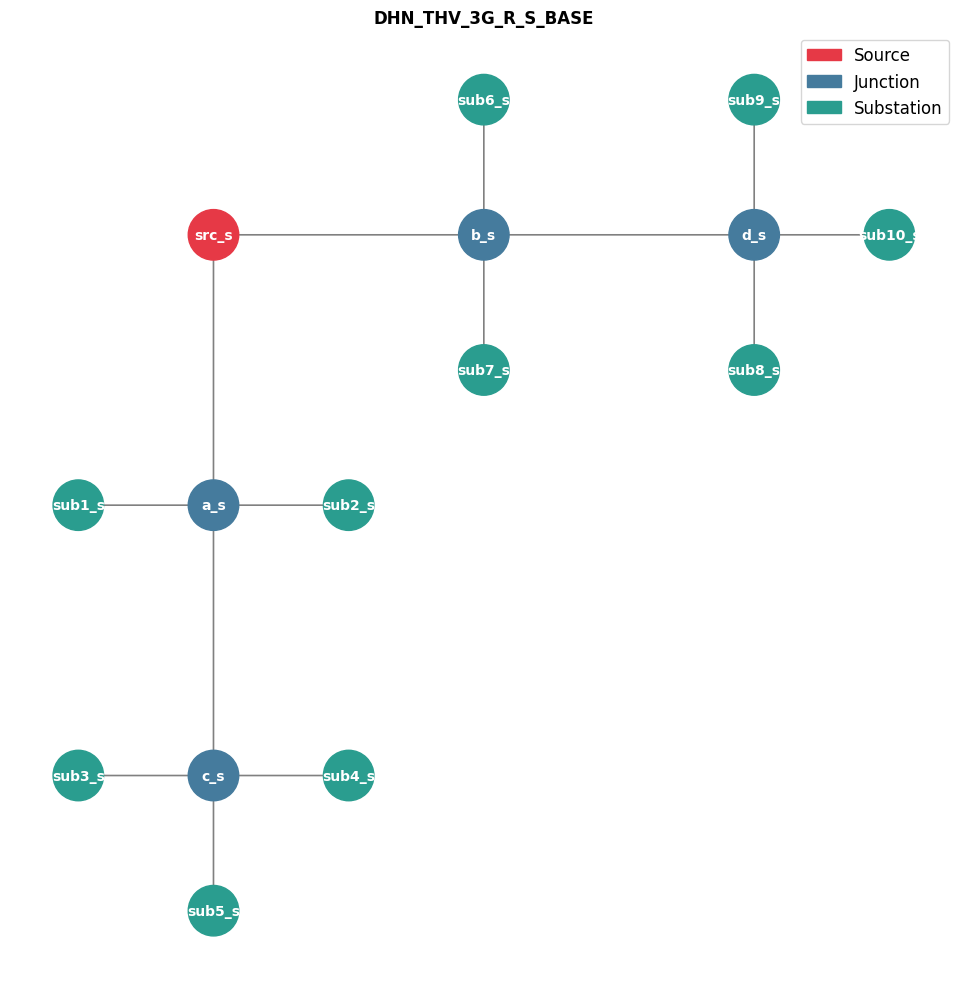

In [5]:
# ---------------------------------------------------------
# TOPOLOGY PLOT
# ---------------------------------------------------------

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

COL = {
    "source"     : "#e63946",
    "junction"   : "#457b9d",
    "substation" : "#2a9d8f",
}

fig, ax = plt.subplots(figsize=(10, 10))

pos_s = {nid: (x, y) for nid, _, x, y in NODES_S}

def draw_edges(edges, pos, color):
    for u, v in edges:
        x1, y1 = pos[u]
        x2, y2 = pos[v]
        ax.annotate("",
            xy    =(x2, -y2),
            xytext=(x1, -y1),
            arrowprops=dict(arrowstyle="-|>", color=color, lw=1.2),
            zorder=2,
        )

def draw_nodes(nodes):
    for nid, ntype, x, y in nodes:
        c = plt.Circle((x, -y), radius=28,
                        color=COL[ntype], zorder=3)
        ax.add_patch(c)
        ax.text(x, -y, nid,
                ha="center", va="center",
                fontsize=10, color="white",
                fontweight="bold", zorder=4)

draw_edges(EDGES_S, pos_s, color="grey")
draw_nodes(NODES_S)

patches = [
    mpatches.Patch(color="#e63946", label="Source"),
    mpatches.Patch(color="#457b9d", label="Junction"),
    mpatches.Patch(color="#2a9d8f", label="Substation"),
]
ax.legend(handles=patches, loc="upper right", fontsize=12)
ax.set_title("DHN_THV_3G_R_S_BASE", fontweight="bold")
ax.set_aspect("equal")
ax.autoscale()
ax.set_frame_on(False)
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()